# Sparse Allreduce analysis

Each experiment runs twice: with a **shared** nonzero pattern (every rank holds the same indices, the best case for sparse communication) and with **independent** patterns (each rank draws its own indices, so the summed result fills in). Batch logs go in `shared/` and `independent/` under the same file names; figures are written to `figures/`. Run this notebook from the `scaling/` directory.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PATTERNS = ["shared", "independent"]
LOGS = {
    "one_layer": "one_layer.txt",
    "two_layer": "two_layer.txt",
    "procs": "procs_res.txt",
    "layers": "layer_res.txt",
    "runtime": "runtime_res.txt",
}
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
color_palette = ['#b5838d', '#7BA05B', '#5B9BD5', '#f4a261', '#6d597a', '#e76f51']

In [2]:
def read_log(path):
    """Parse a batch log into one row per run, or return None if the log has not been collected."""
    path = Path(path)
    if not path.exists():
        return None
    rows, state, run = [], {}, {}
    for line in path.read_text().splitlines():
        line = line.strip()
        key, _, value = line.partition(":")
        value = value.strip()
        if key == "Sparsity level":
            state["sparsity"] = float(value)
        elif key == "Number of elements":
            state["n_elements"] = int(value)
        elif key == "Number of Processes":
            state["n_procs"] = int(value)
        elif line == "Single Layer":
            state["layers"] = 1
        elif line == "Two Layers":
            state["layers"] = 2
        elif key.endswith(" Time") and value.endswith("s"):
            run[key] = float(value[:-1])
        elif key == "Sparse Vector Length":
            run["length"] = int(value)
        elif key == "Mean Input Non-Zero Elements":
            run["input_nnz"] = float(value)
        elif key == "Sparse Vector Non-Zero Elements":
            # Nonzeros in the reduced result
            run["output_nnz"] = int(value)
        elif line == "Results Match!":
            rows.append({**state, **run})
            run = {}
    df = pd.DataFrame(rows).rename(columns={"Sparse Allreduce Time": "sparse_time", "Dense Allreduce Time": "dense_time"})
    if "input_nnz" not in df:
        df["input_nnz"] = np.nan  # Logs from before the input count was printed
    df["speedup"] = df["dense_time"] / df["sparse_time"]
    return df


data = {(name, pattern): read_log(Path(pattern) / filename) for name, filename in LOGS.items() for pattern in PATTERNS}
missing = [f"{pattern}/{LOGS[name]}" for (name, pattern), df in data.items() if df is None]
print("Missing logs:", ", ".join(missing) if missing else "none")

Missing logs: none


In [3]:
def style(ax, xlabel, ylabel, note=None, note_xy=(0.98, 0.04)):
    ax.tick_params(which='major', direction='out', length=4, width=1, colors='dimgray')
    ax.tick_params(which='minor', direction='out', length=2, width=1, colors='dimgray')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    for spine in ax.spines.values():
        spine.set_color('dimgray')
    handles = ax.get_legend_handles_labels()[0]
    if handles:
        legend = ax.legend(fontsize='small', ncols=2 if len(handles) > 6 else 1)
        legend.get_frame().set_linewidth(0.5)
        legend.get_frame().set_edgecolor('gray')
    if note:
        # Anchor the note at whichever corner note_xy is nearest.
        ax.text(*note_xy, note, ha='left' if note_xy[0] < 0.5 else 'right', va='top' if note_xy[1] > 0.5 else 'bottom',
                transform=ax.transAxes, fontsize=8, color='dimgray',
                bbox=dict(facecolor='white', alpha=0.5, edgecolor='gray', boxstyle='round,pad=0.5'))


def pattern_panels(draw, filename, xlabel, ylabel, note, log_x=False, log_y=False):
    """One panel per pattern. draw(ax, pattern) plots one panel and returns False if its log is missing."""
    fig, axes = plt.subplots(1, len(PATTERNS), figsize=(15, 5.5), sharey=True)
    for ax, pattern in zip(axes, PATTERNS):
        if log_x:
            ax.set_xscale("log")
        if log_y:
            ax.set_yscale("log")
        if not draw(ax, pattern):
            ax.text(0.5, 0.5, "Not collected yet", ha="center", va="center", transform=ax.transAxes, color="dimgray")
        ax.set_title(f"{pattern.capitalize()} pattern")
        style(ax, xlabel, ylabel if ax is axes[0] else "", note)
    fig.tight_layout()
    fig.savefig(FIG_DIR / filename, bbox_inches="tight")
    plt.show()


def by_sparsity(df):
    """Yield (colour, sparsity, rows) for each sparsity level in increasing order."""
    for color, (sparsity, group) in zip(color_palette, df.groupby("sparsity")):
        yield color, sparsity, group

## 1. Sparsity and vector length

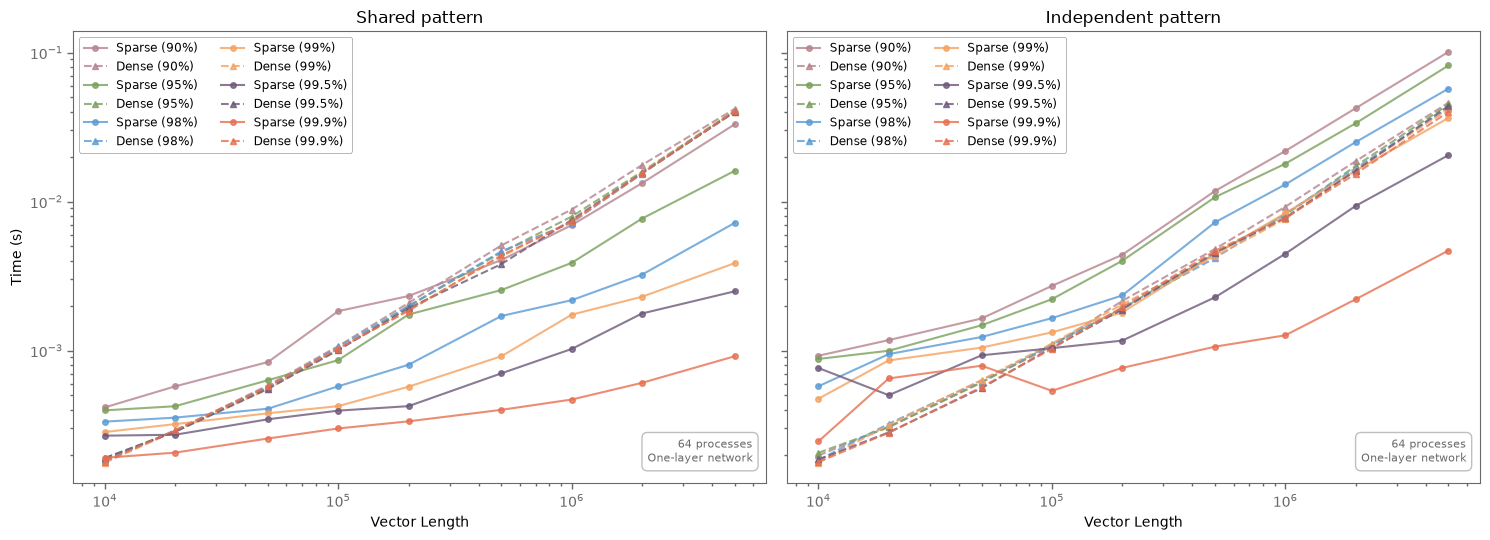

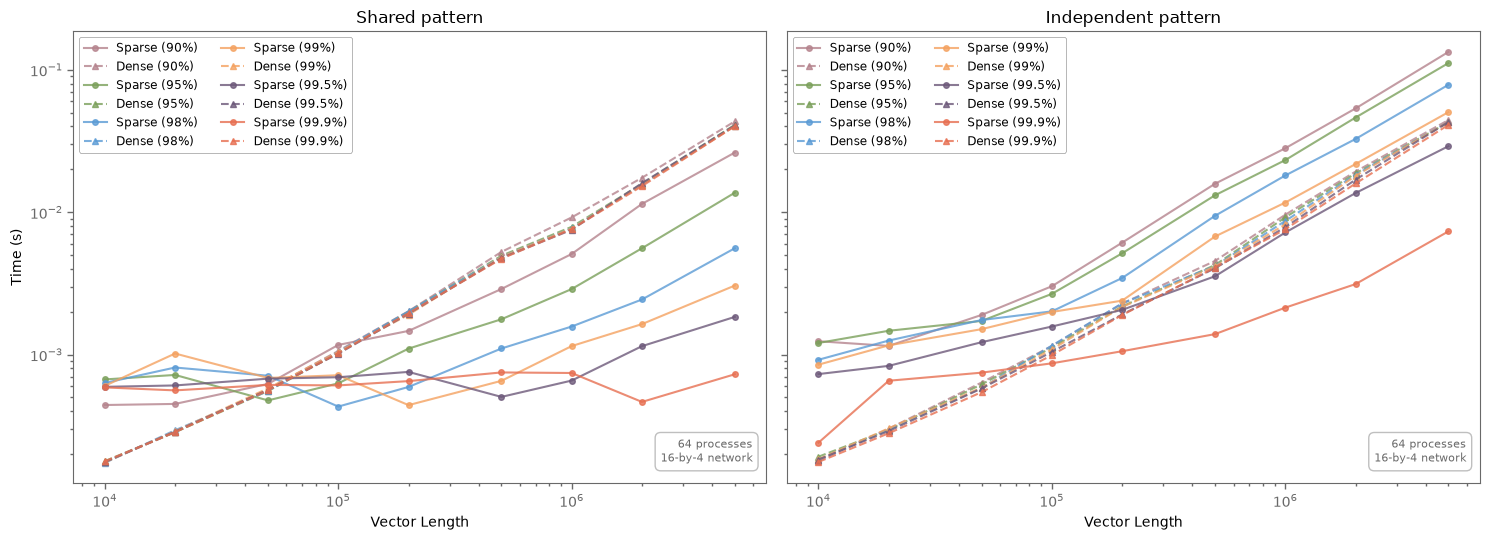

In [4]:
def draw_times(log, x):
    def draw(ax, pattern):
        df = data[log, pattern]
        if df is None:
            return False
        for color, sparsity, group in by_sparsity(df):
            group = group.sort_values(x)
            ax.plot(group[x], group["sparse_time"], 'o-', color=color, markersize=4, alpha=0.8, label=f"Sparse ({sparsity:g}%)")
            ax.plot(group[x], group["dense_time"], '^--', color=color, markersize=4, alpha=0.8, label=f"Dense ({sparsity:g}%)")
        return True
    return draw


pattern_panels(draw_times("one_layer", "n_elements"), "sparsity_one.png", "Vector Length", "Time (s)",
               "64 processes\nOne-layer network", log_x=True, log_y=True)
pattern_panels(draw_times("two_layer", "n_elements"), "sparsity_two.png", "Vector Length", "Time (s)",
               "64 processes\n16-by-4 network", log_x=True, log_y=True)

## 2. Network configuration

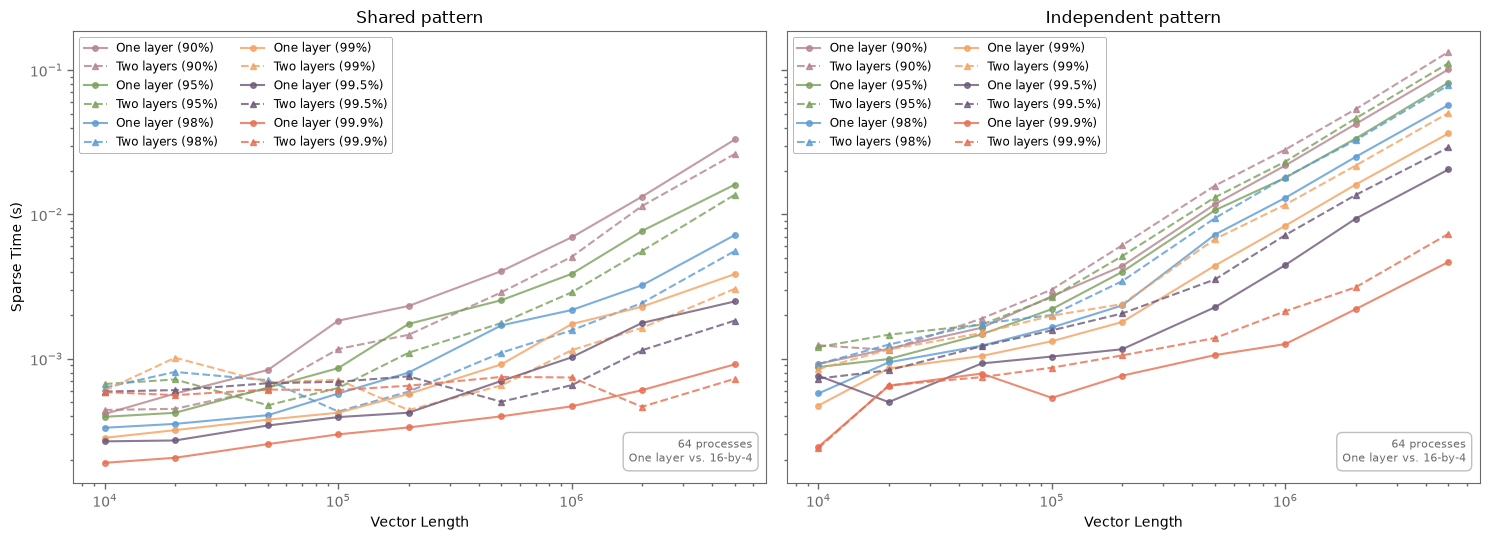

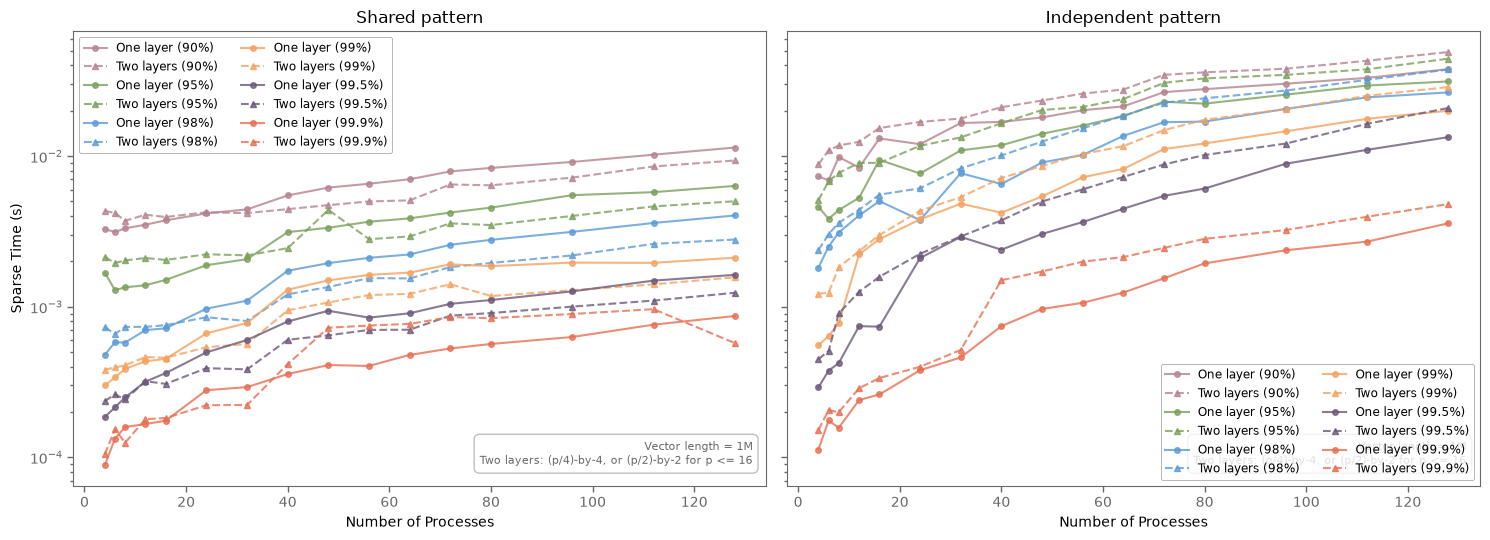

shared: one layer is faster in 39 of 96 configurations
independent: one layer is faster in 95 of 96 configurations


In [5]:
def draw_networks_by_length(ax, pattern):
    one, two = data["one_layer", pattern], data["two_layer", pattern]
    if one is None or two is None:
        return False
    for color, sparsity, group in by_sparsity(one):
        group = group.sort_values("n_elements")
        other = two[two["sparsity"] == sparsity].sort_values("n_elements")
        ax.plot(group["n_elements"], group["sparse_time"], 'o-', color=color, markersize=4, alpha=0.8, label=f"One layer ({sparsity:g}%)")
        ax.plot(other["n_elements"], other["sparse_time"], '^--', color=color, markersize=4, alpha=0.8, label=f"Two layers ({sparsity:g}%)")
    return True


def draw_networks_by_procs(ax, pattern):
    df = data["layers", pattern]
    if df is None:
        return False
    for color, sparsity, group in by_sparsity(df):
        times = group.pivot_table(index="n_procs", columns="layers", values="sparse_time")
        ax.plot(times.index, times[1], 'o-', color=color, markersize=4, alpha=0.8, label=f"One layer ({sparsity:g}%)")
        ax.plot(times.index, times[2], '^--', color=color, markersize=4, alpha=0.8, label=f"Two layers ({sparsity:g}%)")
    return True


pattern_panels(draw_networks_by_length, "network.png", "Vector Length", "Sparse Time (s)",
               "64 processes\nOne layer vs. 16-by-4", log_x=True, log_y=True)
pattern_panels(draw_networks_by_procs, "network_comparison.png", "Number of Processes", "Sparse Time (s)",
               "Vector length = 1M\nTwo layers: (p/4)-by-4, or (p/2)-by-2 for p <= 16", log_y=True)

for pattern in PATTERNS:
    df = data["layers", pattern]
    if df is not None:
        times = df.pivot_table(index=["sparsity", "n_procs"], columns="layers", values="sparse_time")
        print(f"{pattern}: one layer is faster in {(times[1] < times[2]).sum()} of {len(times)} configurations")

## 3. Number of processes

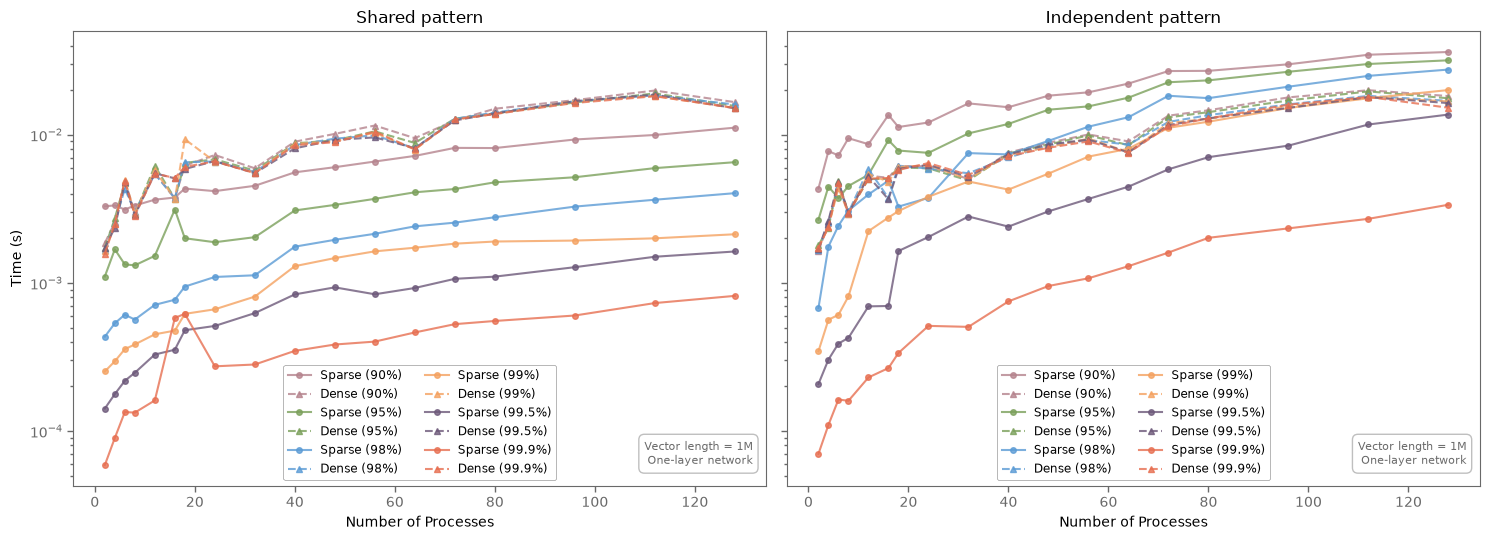

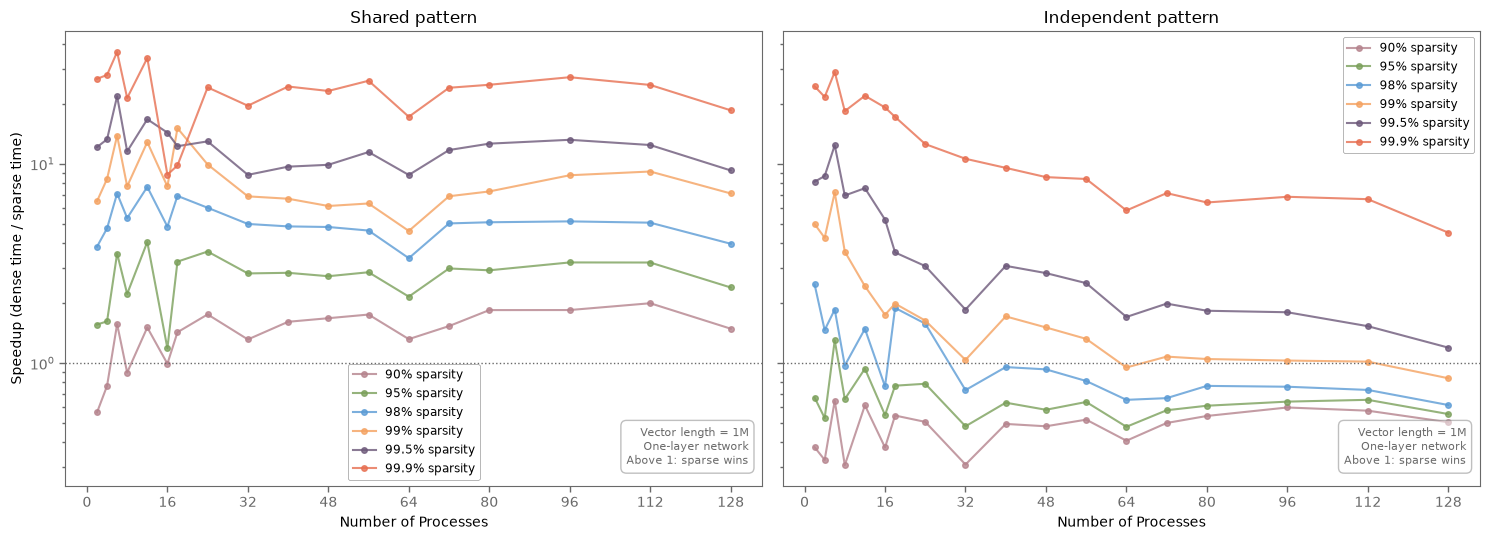

In [6]:
def draw_speedup(ax, pattern):
    df = data["procs", pattern]
    if df is None:
        return False
    for color, sparsity, group in by_sparsity(df):
        group = group.sort_values("n_procs")
        ax.plot(group["n_procs"], group["speedup"], 'o-', color=color, markersize=4, alpha=0.8, label=f"{sparsity:g}% sparsity")
    ax.axhline(1, color='dimgray', linewidth=1, linestyle=':')
    ax.set_xticks(range(0, 128 + 1, 16))
    return True


pattern_panels(draw_times("procs", "n_procs"), "scalability.png", "Number of Processes", "Time (s)",
               "Vector length = 1M\nOne-layer network", log_y=True)
pattern_panels(draw_speedup, "speedup.png", "Number of Processes", "Speedup (dense time / sparse time)",
               "Vector length = 1M\nOne-layer network\nAbove 1: sparse wins", log_y=True)

## 4. Fill-in

With nonzero fraction $q$ per rank, a shared pattern keeps the result at density $q$. With independent patterns over $p$ ranks, an index is zero only if every rank misses it, so the predicted output density is $1 - (1 - q)^p$. The prediction uses each run's measured mean input density.

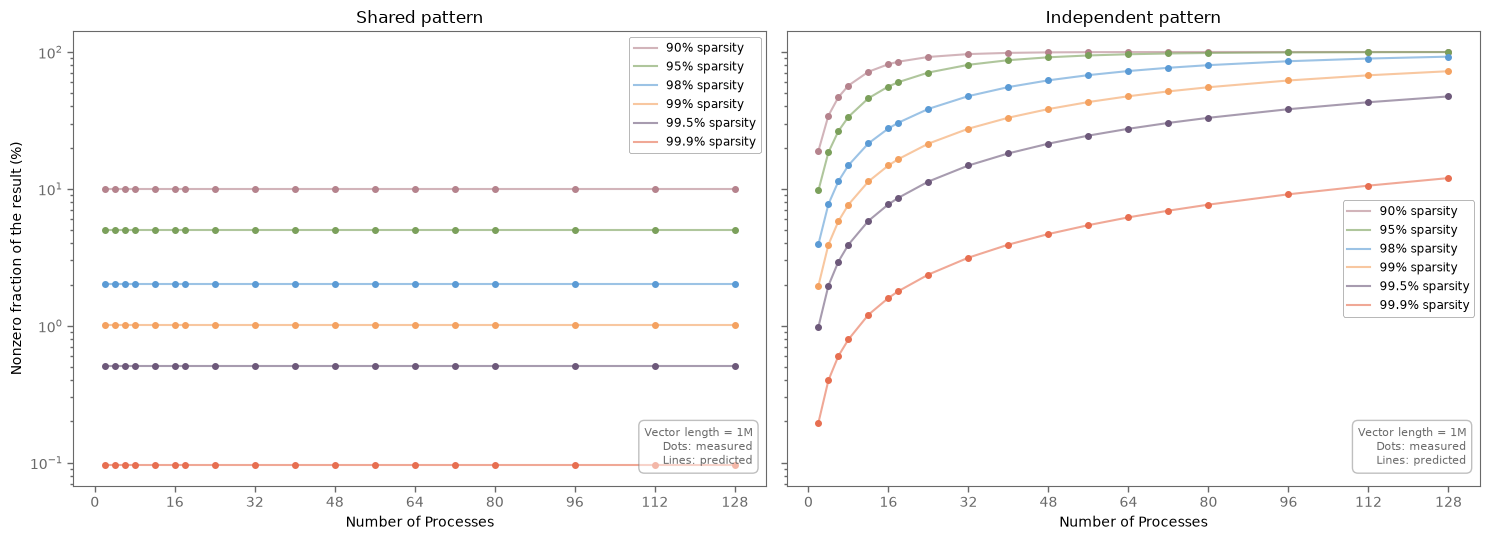

In [7]:
def draw_fill_in(ax, pattern):
    df = data["procs", pattern]
    if df is None:
        return False
    for color, sparsity, group in by_sparsity(df):
        group = group.sort_values("n_procs")
        input_density = (group["input_nnz"] / group["length"]).fillna(1 - sparsity / 100)
        predicted = input_density if pattern == "shared" else 1 - (1 - input_density) ** group["n_procs"]
        ax.plot(group["n_procs"], 100 * group["output_nnz"] / group["length"], 'o', color=color, markersize=4)
        ax.plot(group["n_procs"], 100 * predicted, '-', color=color, alpha=0.6, label=f"{sparsity:g}% sparsity")
    ax.set_xticks(range(0, 128 + 1, 16))
    return True


pattern_panels(draw_fill_in, "fill_in.png", "Number of Processes", "Nonzero fraction of the result (%)",
               "Vector length = 1M\nDots: measured\nLines: predicted", log_y=True)

## 5. Crossover

The crossover is the sparsity at which sparse and dense take the same time. Only six sparsity levels are tested, so for each process count the crossover is reported as a range: between the last level at which sparse loses and the first level from which it wins at every higher level. When sparse already wins at the lowest tested level, the crossover is at or below it (shown as ≤ 90%); when it never wins, the crossover is above the highest level.

In [8]:
def crossover_range(group):
    """Return (last losing level, first winning level) in %, with None for a side outside the tested range."""
    group = group.sort_values("sparsity")
    sparsity = group["sparsity"].to_numpy()
    wins = group["speedup"].to_numpy() >= 1
    if wins.all():
        return None, sparsity[0]
    if not wins[-1]:
        return sparsity[-1], None
    last_loss = len(wins) - 1 - np.argmax(~wins[::-1])
    return sparsity[last_loss], sparsity[last_loss + 1]


def describe_range(loses, wins):
    if loses is None:
        return f"≤ {wins:g}%"
    if wins is None:
        return f"> {loses:g}%"
    return f"{loses:g}–{wins:g}%"


rows = []
for pattern in PATTERNS:
    df = data["procs", pattern]
    if df is None:
        continue
    for n_procs, group in df.groupby("n_procs"):
        rows.append({"pattern": pattern, "n_procs": n_procs, "crossover": describe_range(*crossover_range(group))})
crossovers = pd.DataFrame(rows, columns=["pattern", "n_procs", "crossover"])
crossovers.pivot(index="n_procs", columns="pattern", values="crossover")

pattern,independent,shared
n_procs,,
2,95–98%,90–95%
4,95–98%,90–95%
6,90–95%,≤ 90%
8,98–99%,90–95%
12,95–98%,≤ 90%
16,98–99%,90–95%
18,95–98%,≤ 90%
24,95–98%,≤ 90%
32,98–99%,≤ 90%


## 6. Runtime breakdown

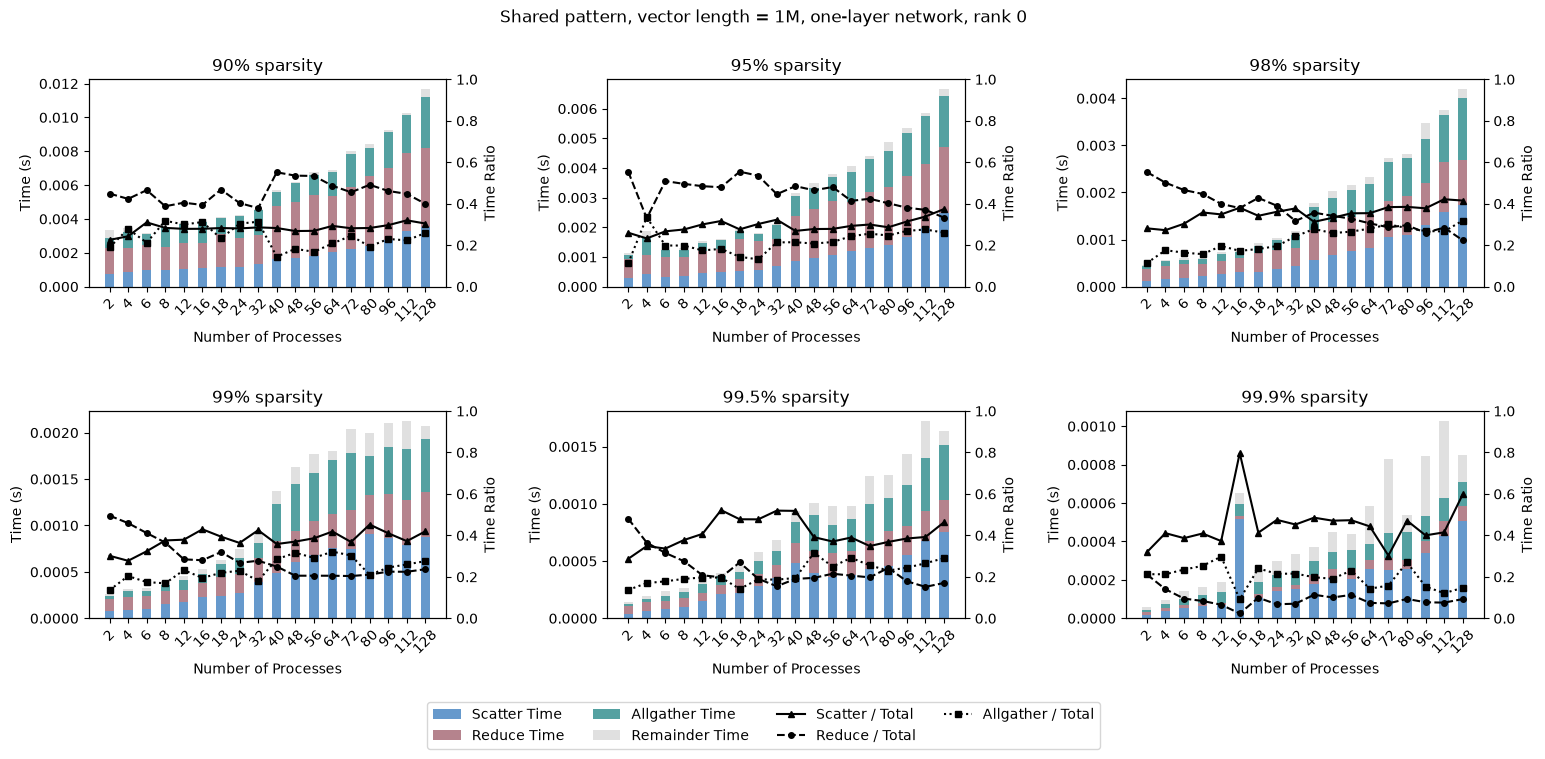

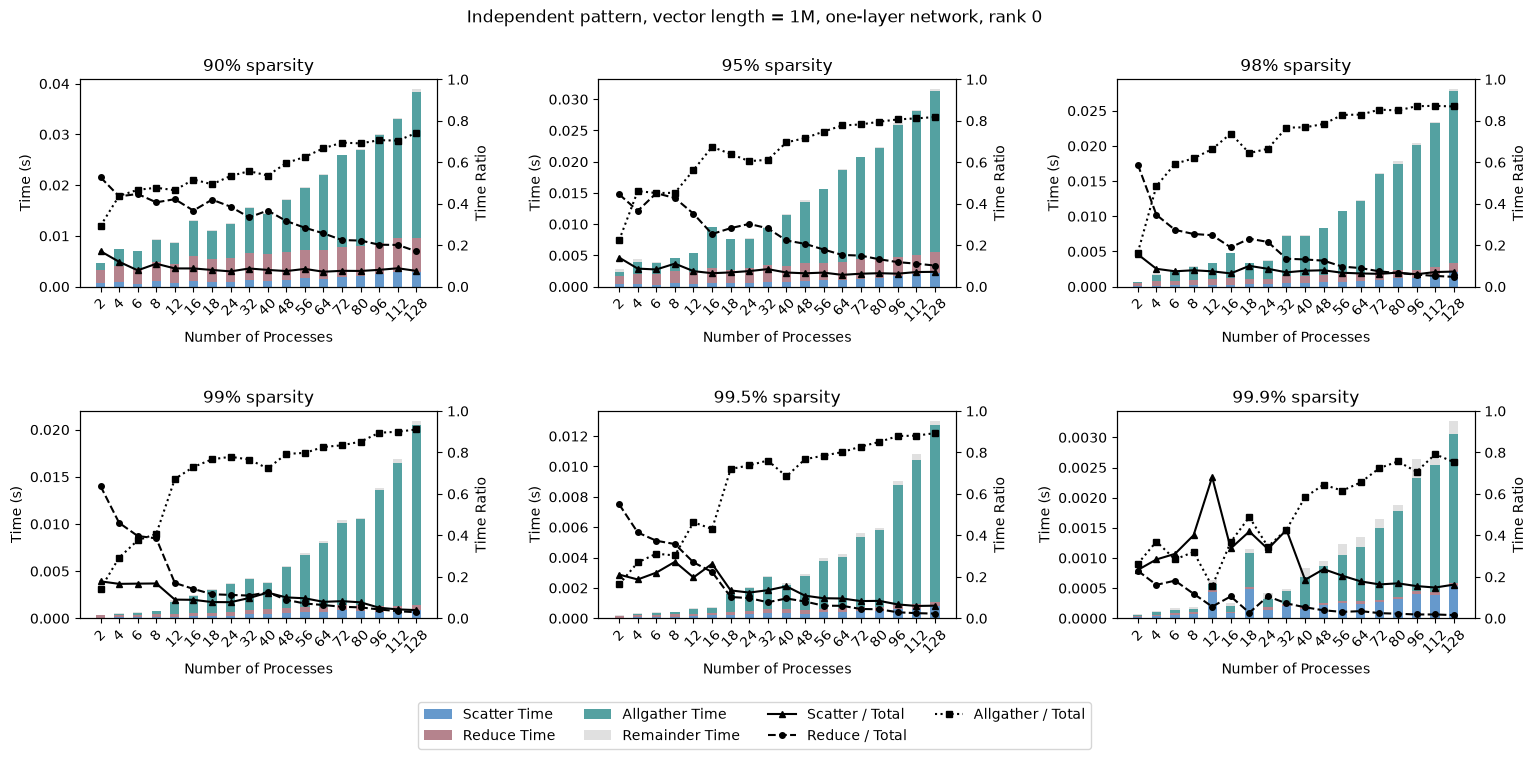

In [9]:
phase_colors = {'Scatter Time': '#6699CC', 'Reduce Time': '#b5838d', 'Allgather Time': '#54a1a1', 'Remainder Time': '#E0E0E0'}

for pattern in PATTERNS:
    df = data["runtime", pattern]
    if df is None:
        print(f"{pattern}/{LOGS['runtime']} not collected yet")
        continue
    df = df.assign(**{"Remainder Time": df["sparse_time"] - df["Scatter Time"] - df["Reduce Time"] - df["Allgather Time"]})
    levels = sorted(df["sparsity"].unique())
    fig, axes = plt.subplots(2, 3, figsize=(18, 7), squeeze=False)
    fig.subplots_adjust(wspace=0.45, hspace=0.6)
    for ax, sparsity in zip(axes.flat, levels):
        group = df[df["sparsity"] == sparsity].sort_values("n_procs")
        x = np.arange(len(group))
        bottom = np.zeros(len(group))
        for phase, color in phase_colors.items():
            ax.bar(x, group[phase], 0.5, bottom=bottom, label=phase, color=color)
            bottom += group[phase].to_numpy()
        ax_ratio = ax.twinx()
        ax_ratio.set_ylim(0, 1)
        ax_ratio.plot(x, group['Scatter Time'] / group['sparse_time'], 'k-^', markersize=4, label='Scatter / Total')
        ax_ratio.plot(x, group['Reduce Time'] / group['sparse_time'], 'k--o', markersize=4, label='Reduce / Total')
        ax_ratio.plot(x, group['Allgather Time'] / group['sparse_time'], 'k:s', markersize=4, label='Allgather / Total')
        ax_ratio.set_ylabel("Time Ratio", fontsize=10)
        ax.set_title(f"{sparsity:g}% sparsity", fontsize=12)
        ax.set_xlabel("Number of Processes", fontsize=10)
        ax.set_ylabel("Time (s)", fontsize=10)
        ax.set_xticks(x)
        ax.set_xticklabels(group["n_procs"], rotation=45)
        if sparsity == levels[0]:
            handles, labels = ax.get_legend_handles_labels()
            ratio_handles, ratio_labels = ax_ratio.get_legend_handles_labels()
    for ax in axes.flat[len(levels):]:
        ax.axis("off")
    fig.legend(handles + ratio_handles, labels + ratio_labels, fontsize=10, loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=4)
    fig.suptitle(f"{pattern.capitalize()} pattern, vector length = 1M, one-layer network, rank 0")
    fig.savefig(FIG_DIR / f"runtime_{pattern}.png", bbox_inches="tight")
    plt.show()